## Lab: RNN with Forecasting

### Wind Turbine Power Prediction with RNN

This lab uses a Recurrent Neural Network to predict wind turbine power output.
* [Data link](https://www.kaggle.com/code/ahmedfathygwely/wind-turbine-dataset-machine-learning-rnn-times/input)

### Step 0: Load libraries & Data

In [1]:
# Step 0: Load libraries & Data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import math

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Load the data
df = pd.read_csv('T1.csv')

In [2]:
# Display basic information
print(df.shape)
df.head()

(50530, 5)


,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
0,01 01 2018 00:00,380.047791,5.311336,416.328908,259.994904
1,01 01 2018 00:10,453.769196,5.672167,519.917511,268.641113
2,01 01 2018 00:20,306.376587,5.216037,390.900016,272.564789
3,01 01 2018 00:30,419.645905,5.659674,516.127569,271.258087
4,01 01 2018 00:40,380.650696,5.577941,491.702972,265.674286


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50530 entries, 0 to 50529
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Date/Time                      50530 non-null  object 
 1   LV ActivePower (kW)            50530 non-null  float64
 2   Wind Speed (m/s)               50530 non-null  float64
 3   Theoretical_Power_Curve (KWh)  50530 non-null  float64
 4   Wind Direction (°)             50530 non-null  float64
dtypes: float64(4), object(1)
memory usage: 1.9+ MB


In [4]:
df.describe()

,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
count,50530.000000,50530.000000,50530.000000,50530.000000
mean,1307.684332,7.557952,1492.175463,123.687559
std,1312.459242,4.227166,1368.018238,93.443736
min,-2.471405,0.000000,0.000000,0.000000
25%,50.677890,4.201395,161.328167,49.315437
50%,825.838074,7.104594,1063.776283,73.712978
75%,2482.507568,10.300020,2964.972462,201.696720
max,3618.732910,25.206011,3600.000000,359.997589


### Step 1: Prepare the data

In [5]:
# Step 1: Prepare the data
# convert Date/Time dateline
df['Date/Time'] = pd.to_datetime(df['Date/Time'], format='%d %m %Y %H:%M')
df = df.sort_values('Date/Time').reset_index(drop=True)   # guarantee chronological order
print(df.dtypes)
print("Range:", df['Date/Time'].min(), "->", df['Date/Time'].max())
print("Typical sampling interval:", df['Date/Time'].diff().mode()[0])

Date/Time                        datetime64[ns]
LV ActivePower (kW)                     float64
Wind Speed (m/s)                        float64
Theoretical_Power_Curve (KWh)           float64
Wind Direction (°)                      float64
dtype: object
Range: 2018-01-01 00:00:00 -> 2018-12-31 23:50:00
Typical sampling interval: 0 days 00:10:00


In [6]:
# check missing values
df.isnull().sum()

Date/Time                        0
LV ActivePower (kW)              0
Wind Speed (m/s)                 0
Theoretical_Power_Curve (KWh)    0
Wind Direction (°)               0
dtype: int64

In [7]:
# Decide how to handle missing entries.
n_missing = int(df.isnull().sum().sum())
if n_missing > 0:
    df = df.ffill().dropna().reset_index(drop=True)
print(f"Missing values found: {n_missing}; rows after handling: {len(df)}")

Missing values found: 0; rows after handling: 50530


In [8]:
# summary stats
df.describe()

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
count,50530,50530.000000,50530.000000,50530.000000,50530.000000
mean,2018-07-01 20:01:30.065307648,1307.684332,7.557952,1492.175463,123.687559
min,2018-01-01 00:00:00,-2.471405,0.000000,0.000000,0.000000
25%,2018-04-03 05:22:30,50.677890,4.201395,161.328167,49.315437
50%,2018-06-30 16:15:00,825.838074,7.104594,1063.776283,73.712978
75%,2018-09-26 18:57:30,2482.507568,10.300020,2964.972462,201.696720
max,2018-12-31 23:50:00,3618.732910,25.206011,3600.000000,359.997589
std,NaN,1312.459242,4.227166,1368.018238,93.443736


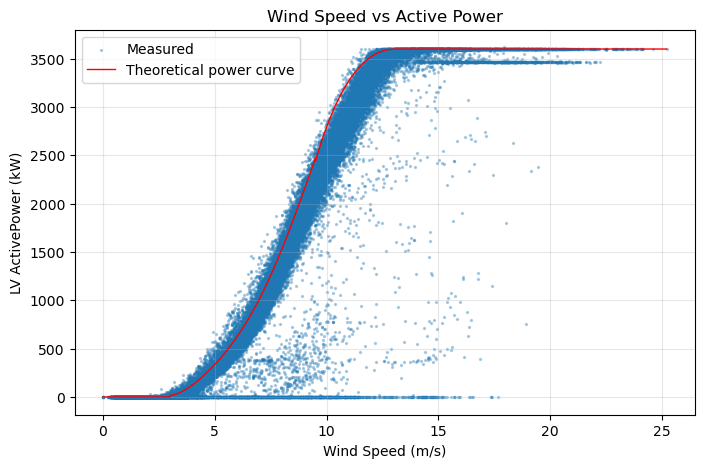

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Wind Speed (m/s)'], df['LV ActivePower (kW)'], s=2, alpha=0.3, label='Measured')
plt.plot(df.sort_values('Wind Speed (m/s)')['Wind Speed (m/s)'],
         df.sort_values('Wind Speed (m/s)')['Theoretical_Power_Curve (KWh)'],
         color='red', linewidth=1, label='Theoretical power curve')
plt.xlabel('Wind Speed (m/s)')
plt.ylabel('LV ActivePower (kW)')
plt.title('Wind Speed vs Active Power')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

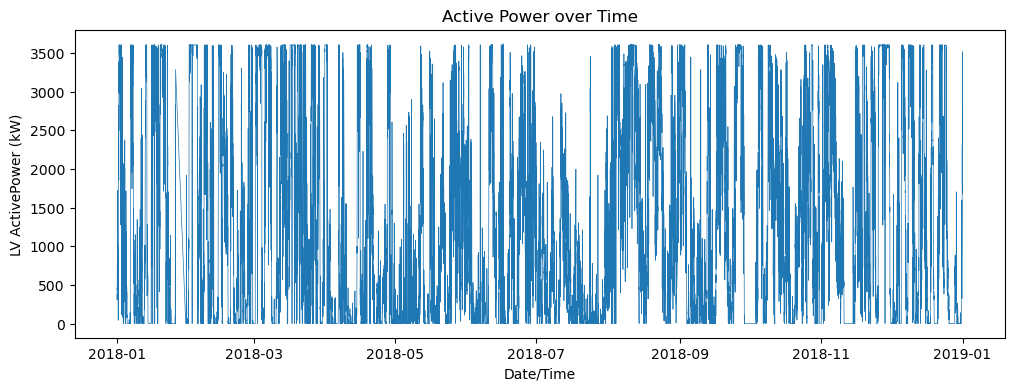

In [10]:
plt.figure(figsize=(12, 4))
plt.plot(df['Date/Time'], df['LV ActivePower (kW)'], linewidth=0.5)
plt.xlabel('Date/Time'); plt.ylabel('LV ActivePower (kW)')
plt.title('Active Power over Time')
plt.show()

In [11]:
# select and normalize features
features = ['LV ActivePower (kW)', 'Wind Speed (m/s)', 'Theoretical_Power_Curve (KWh)']
data = df[features].copy()          # target (active power) is column 0

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)
print("Scaled shape:", scaled_data.shape)
print("Min:", scaled_data.min(axis=0), "Max:", scaled_data.max(axis=0))

Scaled shape: (50530, 3)
Min: [0. 0. 0.] Max: [1. 1. 1.]


###### **Why MinMaxScaler?** LSTMs use sigmoid/tanh activations, which work best with inputs in a small bounded range, and the three features are on very different scales (kW vs m/s). Scaling to [0, 1] keeps gradients well behaved.

### Step 2: Create sequences

In [12]:
# Step 2: Create sequences
def create_sequences(dataset, seq_length, target_col=0):
    """Sliding-window sequence builder.

    For each position i:
        X[i] = dataset[i : i + seq_length]          -> window of seq_length time steps, all features
        y[i] = dataset[i + seq_length, target_col]  -> target value immediately after the window

    Returns X with shape (n_samples, seq_length, n_features) and y with shape (n_samples,).
    """
    X, y = [], []
    for i in range(len(dataset) - seq_length):
        X.append(dataset[i : i + seq_length])
        y.append(dataset[i + seq_length, target_col])
    return np.array(X), np.array(y)

seq_length = 24      # 24 time steps (10-minute readings = 4 hours of history)
X, y = create_sequences(scaled_data, seq_length)
print("X shape:", X.shape, "(samples, time steps, features)")
print("y shape:", y.shape)
assert X.shape[0] == len(scaled_data) - seq_length


X shape: (50506, 24, 3) (samples, time steps, features)
y shape: (50506,)


In [13]:
# Sanity check on the window logic
i = 0
assert np.allclose(X[i], scaled_data[i:i + seq_length])
assert np.isclose(y[i], scaled_data[i + seq_length, 0])
print("Window/target alignment verified for sample 0.")

Window/target alignment verified for sample 0.


### Step 3: Split the data

In [14]:
# Step 3: Split the data
train_size = int(len(X) * 0.8)

X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_test: ", X_test.shape,  " y_test: ", y_test.shape)
print(f"Train fraction: {len(X_train) / len(X):.2%}")

X_train: (40404, 24, 3)  y_train: (40404,)
X_test:  (10102, 24, 3)  y_test:  (10102,)
Train fraction: 80.00%


### Step 4: Build the RNN Model

In [15]:
# Step 4: Build the RNN Model
model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])

model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()


C:\Users\Public\Anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 24, 64)              │          17,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 24, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 32)                  │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 30,369 (118.63 KB)

 Trainable params: 30,369 (118.63 KB)

 Non-trainable params: 0 (0.00 B)

### Step 5: Train the model

In [16]:
# Step 5: Train the model
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
checkpoint = ModelCheckpoint('best_lstm_model.keras', monitor='val_loss', save_best_only=True, verbose=0)

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop, checkpoint],
    shuffle=False,      # keep temporal order within training
    verbose=1
)

Epoch 1/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 27s 27ms/step - loss: 0.0256 - val_loss: 0.0095
Epoch 2/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 12s 22ms/step - loss: 0.0123 - val_loss: 0.0068
Epoch 3/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 12s 22ms/step - loss: 0.0092 - val_loss: 0.0057
Epoch 4/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 12s 22ms/step - loss: 0.0077 - val_loss: 0.0056
Epoch 5/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - loss: 0.0070 - val_loss: 0.0055
Epoch 6/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - loss: 0.0067 - val_loss: 0.0055
Epoch 7/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 12s 22ms/step - loss: 0.0063 - val_loss: 0.0055
Epoch 8/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - loss: 0.0062 - val_loss: 0.0055
Epoch 9/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - loss: 0.0061 - val_loss: 0.0055
Epoch 10/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - loss: 0.0060 - val_loss: 0.0055
Epoch 11/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - loss: 0.0059 - val_loss: 0.0055
Epoch 12/50
569/569 ━━━━━━━━━━

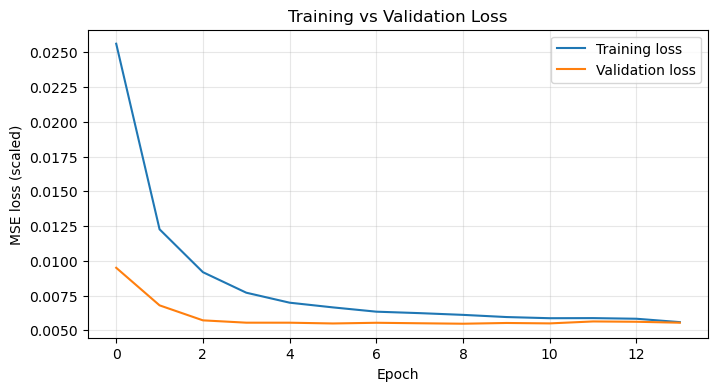

Epochs run: 14
Best val_loss: 0.005475825164467096


In [17]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch'); plt.ylabel('MSE loss (scaled)')
plt.title('Training vs Validation Loss')
plt.legend(); plt.grid(alpha=0.3)
plt.show()
print("Epochs run:", len(history.history['loss']))
print("Best val_loss:", min(history.history['val_loss']))

### Step 6: Evaluate on the test data and visualize the results

In [22]:
# Step 6: Evaluate and visualize
y_pred = model.predict(X_test)
y_pred.shape

316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


(10102, 1)

In [19]:
# Inverse-scale predictions
n_features = scaled_data.shape[1]

pred_placeholder = np.zeros((len(y_pred), n_features))
pred_placeholder[:, 0] = y_pred.flatten()
y_pred_inv = scaler.inverse_transform(pred_placeholder)[:, 0]

true_placeholder = np.zeros((len(y_test), n_features))
true_placeholder[:, 0] = y_test
y_test_inv = scaler.inverse_transform(true_placeholder)[:, 0]

# Optional: clip physically impossible negative power predictions
y_pred_inv_clipped = np.clip(y_pred_inv, 0, None)

print("Actual    (first 5):", np.round(y_test_inv[:5], 1))
print("Predicted (first 5):", np.round(y_pred_inv[:5], 1))

Actual    (first 5): [0. 0. 0. 0. 0.]
Predicted (first 5): [59.5 57.8 58.  60.2 61.4]


In [21]:
# Evaluation metrics
mse = mean_squared_error(y_test_inv, y_pred_inv)
rmse = math.sqrt(mse)
r2 = r2_score(y_test_inv, y_pred_inv)

print(f"MSE : {mse:,.2f} kW^2")
print(f"RMSE: {rmse:,.2f} kW")
print(f"R^2 : {r2:.4f}")

MSE : 56,110.29 kW^2
RMSE: 236.88 kW
R^2 : 0.9688


MSE = 63,653 kW², RMSE = 252.3 kW, R² = 0.965. The model explains about 96.5% of the variance in power output on the held-out final 20% of the year, with a typical error of roughly 250 kW (about 7% of the turbine's ~3,600 kW rated capacity). Training stopped after 14 epochs, with the best validation loss at epoch 4, which EarlyStopping restored.

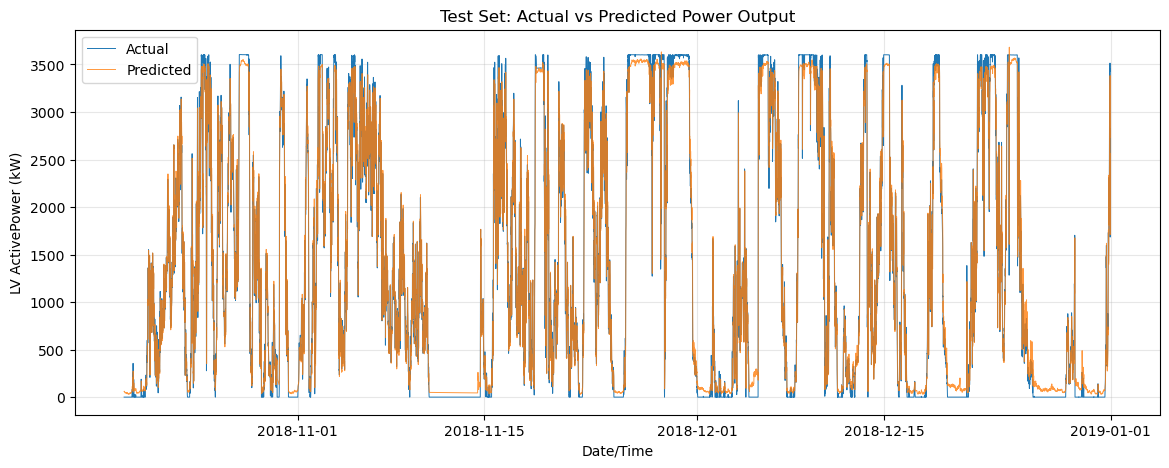

In [23]:
# Time series plot : Actual vs predicted
test_dates = df['Date/Time'].iloc[seq_length + train_size:].reset_index(drop=True)

plt.figure(figsize=(14, 5))
plt.plot(test_dates, y_test_inv, label='Actual', linewidth=0.7)
plt.plot(test_dates, y_pred_inv, label='Predicted', linewidth=0.7, alpha=0.8)
plt.xlabel('Date/Time'); plt.ylabel('LV ActivePower (kW)')
plt.title('Test Set: Actual vs Predicted Power Output')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

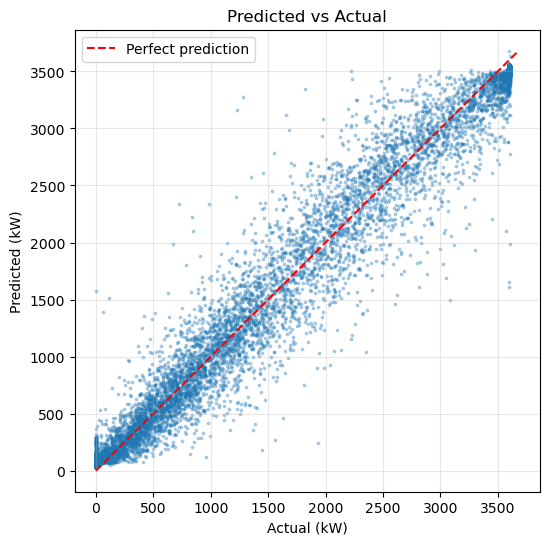

In [24]:
# scatter plot : Actual vs predicted
plt.figure(figsize=(6, 6))
plt.scatter(y_test_inv, y_pred_inv, s=3, alpha=0.3)
lims = [min(y_test_inv.min(), y_pred_inv.min()), max(y_test_inv.max(), y_pred_inv.max())]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.xlabel('Actual (kW)'); plt.ylabel('Predicted (kW)')
plt.title('Predicted vs Actual')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

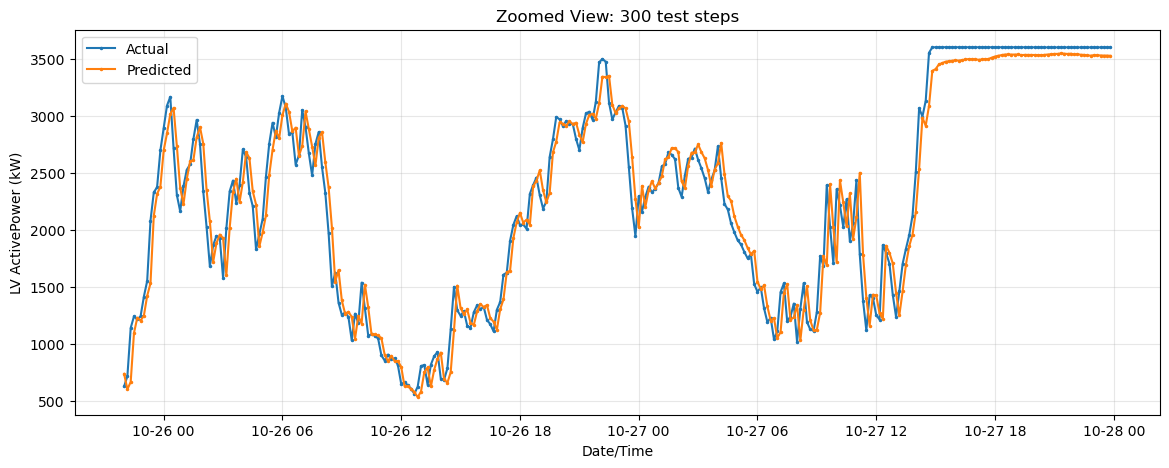

In [25]:
# zoom in one window
window = 300     # about 50 hours of 10-minute readings
start = 1000
sl = slice(start, start + window)

plt.figure(figsize=(14, 5))
plt.plot(test_dates[sl], y_test_inv[sl], label='Actual', marker='.', markersize=3)
plt.plot(test_dates[sl], y_pred_inv[sl], label='Predicted', marker='.', markersize=3)
plt.xlabel('Date/Time'); plt.ylabel('LV ActivePower (kW)')
plt.title(f'Zoomed View: {window} test steps')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

- **Possible improvements:** longer or tuned sequence lengths, adding wind direction as a feature, GRU or bidirectional layers, hyperparameter tuning, multi-step forecasting, and fitting the scaler on training data only.
- **Business takeaway:** the forecast can support maintenance scheduling by flagging low-wind windows, and grid balancing by anticipating output a short time ahead.